# 04 · External-data validation on the full ETH data set (Ti6Al4V + Ck45)
Goal: compare the **slide model's** input→output map with published orthogonal-cutting data, find *where and how* it disagrees, and choose correction factors by **held-out** error, physical sense, and a one-line link to a violated slide assumption.

**Data:** `data/eth_full.csv` is all 519 tests of Klippel et al. (ETH Zürich, arXiv:2209.04197, App. B), extracted with `datapipe.parse_eth_pdf`. 0 rows were unparsed, and the extraction matches the 22 hand-transcribed rows exactly. Forces are **N per mm of width** (App. B text and the raw-data header say "Fp [N/mm]"), so `w_mm = 1`. Tube cutting, γ0 = 0°, uncoated carbide CCMW 09T304 H13A, rn ≈ 25–45 µm.

**Scope rules enforced** (`datapipe.apply_scope`, every drop logged):
* status `ok` only, or `short` with force CV ≤ 5 %
* BUE-suspect Ck45 rows dropped (vc ≤ 100, or vc ≤ 150 with f ≤ 0.02)
* heavy wear (class H) dropped
* non-positive forces dropped

Corrections are **empirical, lumped** factors. They are not thermal or wear models; those stay out of scope.

In [1]:
import sys; sys.path.insert(0, '.')
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from datapipe import *; from calibrate import *; from orthocut import *
pd.set_option('display.width', 200); plt.rcParams['figure.dpi'] = 90
raw = load_csv('data/eth_full.csv')
SIGMA_Y = {'Ti6Al4V': 869.0, 'Ck45': 420.0}                      # ETH Table 2 (supplier, 0.2 % offset)
JC = {'Ti6Al4V': (867, 344, 0.361), 'Ck45': (392, 735, 0.304)}    # ETH Table 6 (A, B, n)
D, MAT = {}, {}
for m in ['Ti6Al4V', 'Ck45']:
    print(f'--- {m}'); k, dr = apply_scope(raw[raw.material == m])
    d = to_twin_units(k); d['Vc_m_min'] = d.vc_m_min.round(0)       # merge 159.1/162 etc. into speed groups
    D[m] = d; MAT[m] = Material(m, SIGMA_Y[m]/np.sqrt(3), SIGMA_Y[m])
    print(f'speeds: {sorted(d.Vc_m_min.unique().astype(int))}\nfeeds : {sorted(d.t_mm.unique())}\n')

--- Ti6Al4V
kept 273 / 287 rows; dropped 14
drop_reason
status;nonpositive_force;    6
status;wear;                 4
short_unstable;              3
short_unstable;wear;         1
speeds: [np.int64(10), np.int64(13), np.int64(20), np.int64(40), np.int64(50), np.int64(52), np.int64(60), np.int64(70), np.int64(74), np.int64(80), np.int64(89), np.int64(100), np.int64(125), np.int64(150), np.int64(159), np.int64(162), np.int64(190), np.int64(200), np.int64(212), np.int64(254), np.int64(318), np.int64(381), np.int64(400), np.int64(500)]
feeds : [np.float64(0.01), np.float64(0.02), np.float64(0.03), np.float64(0.04), np.float64(0.06), np.float64(0.08), np.float64(0.1), np.float64(0.12), np.float64(0.15), np.float64(0.2), np.float64(0.4)]

--- Ck45
kept 95 / 232 rows; dropped 137
drop_reason
BUE;                             95
status;BUE;                      27
status;                           6
short_unstable;BUE;               4
status;nonpositive_force;         2
status;BUE;nonpositive_f

## 1 · What the data say, before any model
The slide model gives Pz ∝ t with **zero intercept**, and a **constant** apparent μ = Pxy/Pz (γ0 = 0).

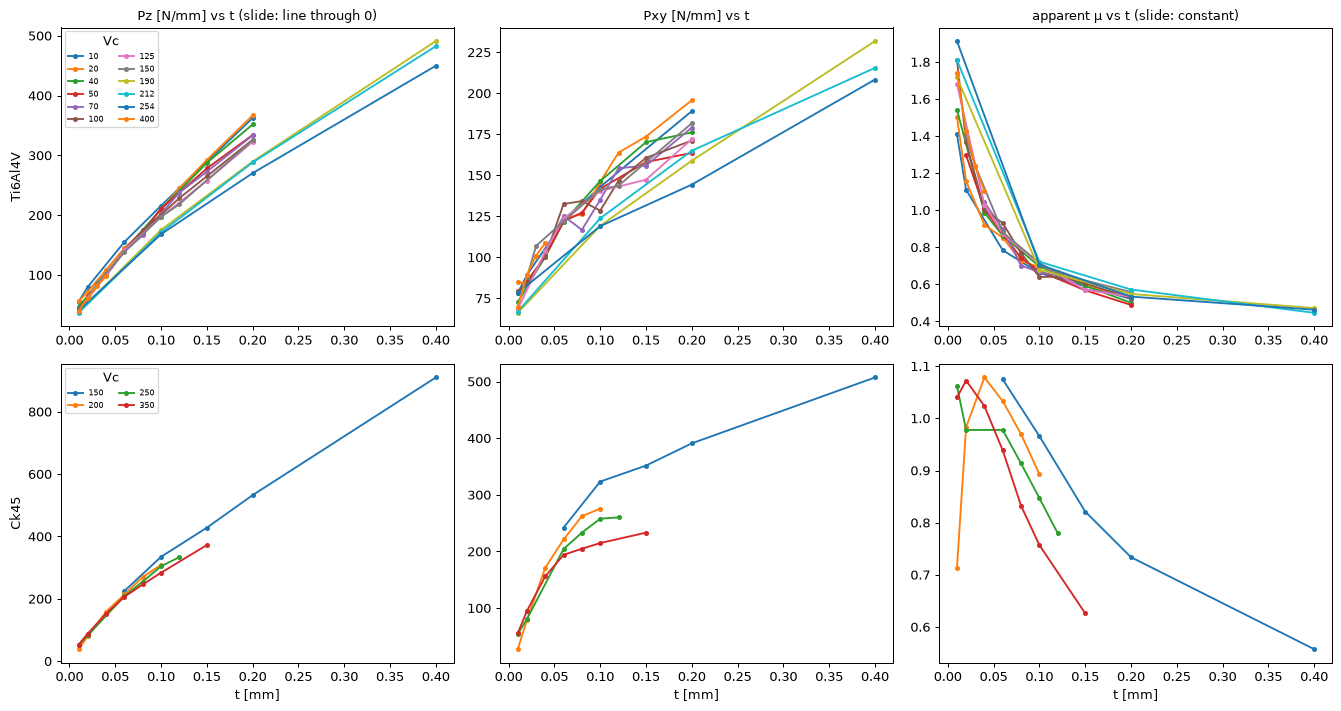

,material,Vc,n,Pz_slope,Pz_icpt,Pxy_slope,Pxy_icpt
0,Ti6Al4V,10.0,18,1599.6,50.3,576.0,80.4
1,Ti6Al4V,20.0,28,1648.9,42.8,624.9,79.2
2,Ti6Al4V,40.0,18,1611.3,39.5,545.7,80.4
3,Ti6Al4V,50.0,21,1505.8,45.9,430.6,88.4
4,Ti6Al4V,70.0,20,1460.7,51.0,464.5,88.4
5,Ti6Al4V,100.0,27,1495.7,41.8,489.3,84.0
6,Ti6Al4V,125.0,18,1445.5,41.8,480.8,81.1
7,Ti6Al4V,150.0,17,1434.3,44.8,484.8,87.5
8,Ti6Al4V,400.0,12,1950.0,21.9,1299.0,59.7
9,Ck45,150.0,17,2082.6,117.8,865.4,222.0


In [2]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for i, (m, d) in enumerate(D.items()):
    for V, g in d.groupby('Vc_m_min'):
        if g.t_mm.nunique() >= 4:
            g = g.groupby('t_mm', as_index=False)[['Pz_N', 'Pxy_N', 'mu_app']].mean()
            ax[i, 0].plot(g.t_mm, g.Pz_N, 'o-', ms=3, label=f'{V:g}'); ax[i, 1].plot(g.t_mm, g.Pxy_N, 'o-', ms=3); ax[i, 2].plot(g.t_mm, g.mu_app, 'o-', ms=3)
    ax[i, 0].set_ylabel(m); ax[i, 0].legend(fontsize=6, title='Vc', ncol=2)
for a, ttl in zip(ax[0], ['Pz [N/mm] vs t (slide: line through 0)', 'Pxy [N/mm] vs t', 'apparent μ vs t (slide: constant)']): a.set_title(ttl, fontsize=10)
for a in ax[1]: a.set_xlabel('t [mm]')
plt.tight_layout(); plt.show()
rows = []
for m, d in D.items():
    for V, g in d[d.t_mm <= 0.2].groupby('Vc_m_min'):
        if g.t_mm.nunique() >= 4:
            pz = np.polyfit(g.t_mm, g.Pz_N, 1); px = np.polyfit(g.t_mm, g.Pxy_N, 1)
            rows.append(dict(material=m, Vc=V, n=len(g), Pz_slope=pz[0], Pz_icpt=pz[1], Pxy_slope=px[0], Pxy_icpt=px[1]))
pd.DataFrame(rows).round(1)

**Reading:** both materials show (i) clearly non-zero force intercepts at t → 0, and (ii) apparent μ falling strongly with t, from ≈ 1–2 at t = 0.01 mm to ≈ 0.4–0.6 at t ≥ 0.2 mm. The slide model can do neither. Ck45 thrust also falls markedly with speed.

Violated slide assumptions:
* *perfectly sharp tool, no flank contact*: edge/ploughing force
* *constant mean friction μ*: μ depends on t (and V)

## 2 · Shear-angle check against measured chip thickness (in-scope test of the slide relations)
Each ETH test has an average chip thickness h. Chip ratio r = t/h gives the measured β, using the slide relation tan β = r cos γ0 / (1 − r sin γ0). We compare it with the slide shear-angle models evaluated at the measured μ_app.

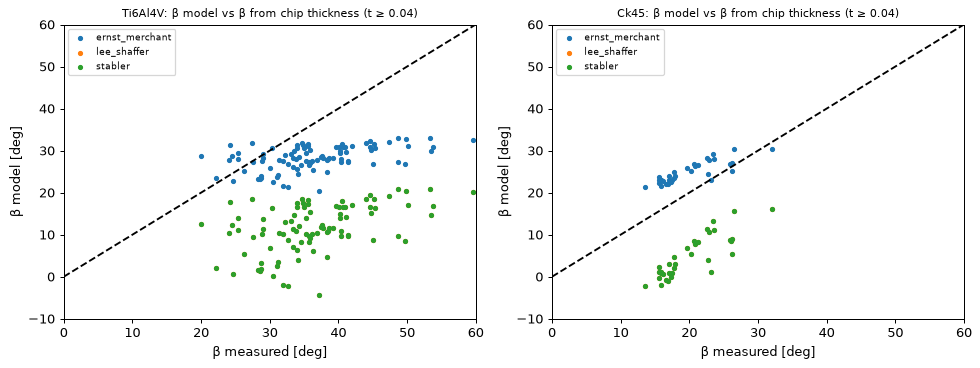

,material,n,beta_meas_median,ernst_merchant_median,lee_shaffer_median,stabler_median,ernst_merchant_MAE,lee_shaffer_MAE,stabler_MAE
0,Ti6Al4V,93,35.6,28.3,11.6,11.6,9.0,24.9,24.9
1,Ck45,34,18.8,24.3,3.6,3.6,5.0,15.2,15.2


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2)); summ = []
for a, (m, d) in zip(ax, D.items()):
    h = d.dropna(subset=['h_chip_um']); h = h[h.t_mm >= 0.04]
    bm = beta_from_chip_ratio(h.t_mm*1000/h.h_chip_um, 0.0); eta = np.arctan(h.mu_app)
    pred = {mdl: np.degrees(shear_angle(mdl, 0.0, eta)) for mdl in ['ernst_merchant', 'lee_shaffer', 'stabler']}
    for mdl, b in pred.items(): a.scatter(bm, b, s=10, label=mdl)
    a.plot([0, 60], [0, 60], 'k--'); a.set_xlim(0, 60); a.set_ylim(-10, 60); a.set_title(f'{m}: β model vs β from chip thickness (t ≥ 0.04)', fontsize=9)
    a.set_xlabel('β measured [deg]'); a.set_ylabel('β model [deg]'); a.legend(fontsize=7)
    summ.append(dict(material=m, n=len(h), beta_meas_median=np.median(bm), **{f'{k}_median': np.median(v) for k, v in pred.items()},
                     **{f'{k}_MAE': np.mean(np.abs(v - bm)) for k, v in pred.items()}))
plt.tight_layout(); plt.show(); pd.DataFrame(summ).round(1)

**Reading:** Ernst–Merchant (2β + η − γ0 = π/2) is the only slide relation that lands in the right range. Lee–Shaffer and Stabler predict β far too small at these μ, so **Ernst–Merchant stays the default shear model.**

Ck45 (continuous chips) is the cleaner test. For Ti6Al4V the "average chip thickness" of a segmented chip is ambiguous, so its β comparison is weak by construction.

## 3 · The τs input: initial yield vs shear-plane flow stress
The slides use τs. Setting τs = σy/√3 assumes the shear plane works at *initial* yield, but chip formation happens at shear strain ≈ 2–3. As a check (not a new model), `tau_s_flow_JC` evaluates the tensile Johnson–Cook hardening curve A + Bεⁿ at the single-shear-plane strain γs = cos γ0 / (sin β cos(β − γ0)). Rate and temperature terms are deliberately left out. We then compare the implied multiplier with the τ_k fitted to forces.

In [4]:
rows = []
for m, d in D.items():
    h = d.dropna(subset=['h_chip_um']); h = h[h.t_mm >= 0.1]
    beta = float(np.median(beta_from_chip_ratio(h.t_mm*1000/h.h_chip_um, 0.0)))
    tjc = tau_s_flow_JC(*JC[m], 0.0, beta)
    pfit = fit(d[d.t_mm >= 0.1], MAT[m], ('mu', 'tau_k', 'Ke_z', 'Ke_xy'))[0]
    rows.append(dict(material=m, sigma_y=SIGMA_Y[m], tau_s_yield=MAT[m].tau_s, beta_meas=beta, tau_s_JC_at_shear_strain=tjc,
                     tau_k_implied_by_JC=tjc/MAT[m].tau_s, tau_k_fitted=pfit['tau_k'], ratio_fit_over_JC=pfit['tau_k']/(tjc/MAT[m].tau_s)))
TAU = pd.DataFrame(rows); TAU.round(3)

,material,sigma_y,tau_s_yield,beta_meas,tau_s_JC_at_shear_strain,tau_k_implied_by_JC,tau_k_fitted,ratio_fit_over_JC
0,Ti6Al4V,869.0,501.717,37.551,712.355,1.420,0.788,0.555
1,Ck45,420.0,242.487,22.561,718.582,2.963,2.711,0.915


**Reading:**
* **Ck45** (continuous chips) needs τ_k ≈ 2.7 on σy/√3. The JC-at-shear-strain estimate gets within roughly 10 % of that without using any force data. τ_k is therefore not a fudge: it is the gap between initial yield and the flow stress the shear plane actually works at.
* **Ti6Al4V** (segmented chips, little hardening, strong adiabatic softening) needs τ_k ≈ 1. The JC estimate overshoots there, which is expected because Ti breaks the continuous-chip assumption.

**Consequence for SS316L.** 316L work-hardens far more strongly (n ≈ 0.61), so σy/√3 alone will under-predict forces by a factor of ~4–5. That answers open issue 2: σy (or the certificate value) sets the *initial* yield, and the effective τs must account for hardening (§7).

## 4 · Ablation with held-out validation
Two held-out tests:
* **LOSO** leaves out one cutting speed at a time
* **LOFO** leaves out one uncut thickness at a time. This is the harder test, because the twin must work at thicknesses it was not tuned on.

| Factor | Violated slide assumption | Form |
|---|---|---|
| `mu`, `tau_k` | μ and τs are unknown *effective* values | μ, τs·k |
| `Ke_z`, `Ke_xy` | tool perfectly sharp, no flank contact | + Ke·w [N] |
| `n_mu` | single constant mean μ on rake face | μ·(t/0.1 mm)^(−n_mu) |
| `c_rate` | τs independent of speed (**lumped**, absorbs thermal/rate effects that are out of scope) | τs·(1 + c ln(Vc/100)) |
| `m_mu` | μ independent of speed (lumped) | μ·(Vc/100)^(−m_mu) |

In [5]:
SETS = {'baseline (μ=0.5, τ_k=1)': None,
        'μ, τ_k': ('mu', 'tau_k'),
        '+ edge force': ('mu', 'tau_k', 'Ke_z', 'Ke_xy'),
        '+ edge + μ(t)': ('mu', 'tau_k', 'Ke_z', 'Ke_xy', 'n_mu'),
        '+ edge + speed (c_rate)': ('mu', 'tau_k', 'Ke_z', 'Ke_xy', 'c_rate'),
        '+ edge + μ(t) + speed + μ(V)': ('mu', 'tau_k', 'Ke_z', 'Ke_xy', 'n_mu', 'c_rate', 'm_mu')}
rows = []
for m, d in D.items():
    for name, free in SETS.items():
        lv = leave_one_group_out(d, MAT[m], free, 'Vc_m_min'); lf = leave_one_group_out(d, MAT[m], free, 't_mm')
        p = {'mu': 0.5} if free is None else fit(d, MAT[m], free)[0]; mi, _ = metrics(d, MAT[m], p)
        rows.append({'material': m, 'model': name, 'k': 0 if free is None else len(free),
                     'LOSO Pz %': lv[0], 'LOSO Pxy %': lv[1], 'LOFO Pz %': lf[0], 'LOFO Pxy %': lf[1],
                     'in-sample Pz %': mi['Pz']['MAPE_pct'], 'in-sample Pxy %': mi['Pxy']['MAPE_pct'],
                     'fitted': {a: round(float(b), 3) for a, b in p.items()}})
ABL = pd.DataFrame(rows); ABL['mean held-out %'] = ABL[['LOSO Pz %', 'LOSO Pxy %', 'LOFO Pz %', 'LOFO Pxy %']].mean(1)
ABL.round(1)

/tmp/ipykernel_105149/3392786724.py:16: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  ABL = pd.DataFrame(rows); ABL['mean held-out %'] = ABL[['LOSO Pz %', 'LOSO Pxy %', 'LOFO Pz %', 'LOFO Pxy %']].mean(1)


,material,model,k,LOSO Pz %,LOSO Pxy %,LOFO Pz %,LOFO Pxy %,in-sample Pz %,in-sample Pxy %,fitted,mean held-out %
0,Ti6Al4V,"baseline (μ=0.5, τ_k=1)",0,29.7,51.1,29.7,51.1,29.7,51.1,{'mu': 0.5},40.4
1,Ti6Al4V,"μ, τ_k",2,28.0,45.3,28.5,48.2,27.6,44.9,"{'mu': 0.591, 'tau_k': 0.962}",37.5
2,Ti6Al4V,+ edge force,4,16.1,10.6,20.1,12.3,15.8,10.4,"{'mu': 0.333, 'tau_k': 0.969, 'Ke_z': 53.461, ...",14.8
3,Ti6Al4V,+ edge + μ(t),5,10.0,7.0,11.4,7.1,9.6,6.9,"{'mu': 0.766, 'tau_k': 0.888, 'Ke_z': 15.343, ...",8.8
4,Ti6Al4V,+ edge + speed (c_rate),5,11.7,9.5,14.8,11.2,11.3,9.3,"{'mu': 0.335, 'tau_k': 0.963, 'Ke_z': 48.022, ...",11.8
5,Ti6Al4V,+ edge + μ(t) + speed + μ(V),7,6.2,6.7,6.7,6.8,5.9,6.6,"{'mu': 0.762, 'tau_k': 0.888, 'Ke_z': 10.923, ...",6.6
6,Ck45,"baseline (μ=0.5, τ_k=1)",0,76.5,86.2,76.5,86.2,76.5,86.2,{'mu': 0.5},81.4
7,Ck45,"μ, τ_k",2,21.4,36.4,21.4,36.2,20.7,34.6,"{'mu': 0.753, 'tau_k': 2.8}",28.8
8,Ck45,+ edge force,4,16.3,35.8,19.7,42.7,15.6,34.2,"{'mu': 0.592, 'tau_k': 2.723, 'Ke_z': 56.385, ...",28.6
9,Ck45,+ edge + μ(t),5,8.6,22.6,9.0,23.6,7.9,21.0,"{'mu': 0.877, 'tau_k': 2.663, 'Ke_z': 13.232, ...",15.9


**Reading (decision rule: a factor stays only if it lowers held-out error on *both* materials, takes a physically sensible value, and maps to a slide assumption):**
* **μ, τ_k**: always needed. These are effective values, not corrections.
* **Thickness term (edge force and/or μ(t))**: the biggest single gain on both materials, in both LOSO and LOFO. Once `n_mu` is free, `Ke_xy` is driven to ≈ 0, and `Ke_z` drops to ≈ 10–15 N/mm. The data cannot separate "ploughing force at the edge" from "μ rising at small t". Both describe the same blunt-edge effect, which dominates when t is comparable to rn ≈ 38 µm.
* **Speed terms (`c_rate`, `m_mu`)**: they help Ti6Al4V (c_rate < 0, i.e. softening) but give **no consistent held-out gain on Ck45**. Their sign and size are material-specific, and physically they stand in for thermal softening, which is out of scope. **Default OFF; report as a sensitivity only.**

**Recommended final factor set: {μ, τ_k, Ke_z, Ke_xy, n_mu}** ("+ edge + μ(t)"). This is a team decision (see hand-off); the table above is the evidence.

== Ti6Al4V: point fit {'mu': 0.766, 'tau_k': 0.888, 'Ke_z': 15.343, 'Ke_xy': 0.0, 'n_mu': 0.419}
        mu  tau_k    Ke_z  Ke_xy   n_mu
5%   0.740  0.838  10.775    0.0  0.414
50%  0.765  0.888  15.358    0.0  0.419
95%  0.794  0.936  20.164    0.0  0.425 



== Ck45: point fit {'mu': 0.877, 'tau_k': 2.663, 'Ke_z': 13.232, 'Ke_xy': 0.0, 'n_mu': 0.266}
        mu  tau_k    Ke_z  Ke_xy   n_mu
5%   0.857  2.642  11.887    0.0  0.237
50%  0.878  2.665  13.132    0.0  0.264
95%  0.895  2.690  14.305    0.0  0.281 



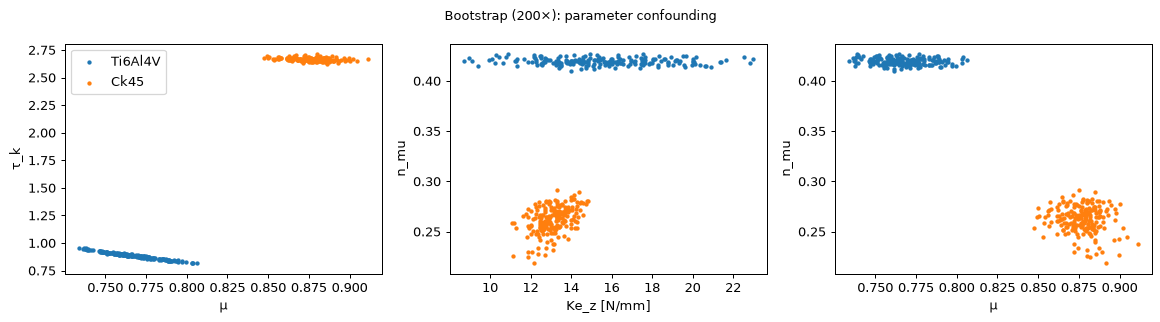

In [6]:
FINAL = SETS['+ edge + μ(t)']
BOOT = {}
for m, d in D.items():
    b = bootstrap(d, MAT[m], FINAL, n=200, seed=1); BOOT[m] = b
    print(f'== {m}: point fit', {k: round(float(v), 3) for k, v in fit(d, MAT[m], FINAL)[0].items()})
    print(b.describe(percentiles=[.05, .5, .95]).loc[['5%', '50%', '95%']].round(3).to_string(), '\n')
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for m, b in BOOT.items():
    ax[0].scatter(b.mu, b.tau_k, s=6, label=m); ax[1].scatter(b.Ke_z, b.n_mu, s=6); ax[2].scatter(b.mu, b.n_mu, s=6)
for a, (x, y) in zip(ax, [('μ', 'τ_k'), ('Ke_z [N/mm]', 'n_mu'), ('μ', 'n_mu')]): a.set_xlabel(x); a.set_ylabel(y)
ax[0].legend(); fig.suptitle('Bootstrap (200×): parameter confounding', fontsize=10); plt.tight_layout(); plt.show()

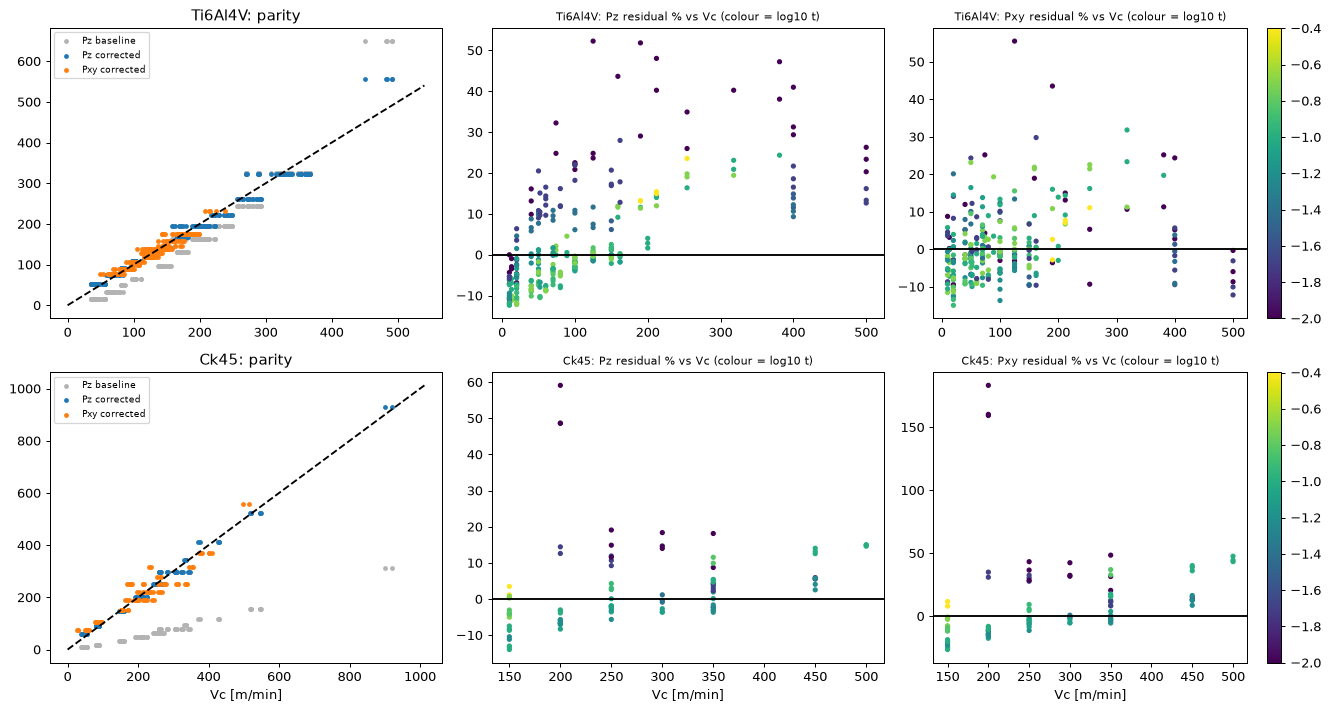

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for i, (m, d) in enumerate(D.items()):
    p = fit(d, MAT[m], FINAL)[0]; _, pr = metrics(d, MAT[m], p); _, pb = metrics(d, MAT[m], {'mu': 0.5})
    mx = max(d.Pz_N.max(), d.Pxy_N.max())*1.1
    ax[i, 0].scatter(d.Pz_N, pb[:, 0], s=8, c='0.7', label='Pz baseline'); ax[i, 0].scatter(d.Pz_N, pr[:, 0], s=8, label='Pz corrected')
    ax[i, 0].scatter(d.Pxy_N, pr[:, 1], s=8, label='Pxy corrected'); ax[i, 0].plot([0, mx], [0, mx], 'k--'); ax[i, 0].set_title(f'{m}: parity'); ax[i, 0].legend(fontsize=7)
    for j, (col, k) in enumerate([('Pz_N', 0), ('Pxy_N', 1)]):
        res = (pr[:, k] - d[col])/d[col]*100
        sc = ax[i, j+1].scatter(d.Vc_m_min, res, c=np.log10(d.t_mm), s=10, cmap='viridis'); ax[i, j+1].axhline(0, c='k')
        ax[i, j+1].set_title(f'{m}: {col[:-2]} residual % vs Vc (colour = log10 t)', fontsize=9)
    plt.colorbar(sc, ax=ax[i, 2])
for a in ax[1]: a.set_xlabel('Vc [m/min]')
plt.tight_layout(); plt.show()

## 5 · Transfer test: do the *geometry* factors carry across materials?
This mimics what happens with SS316L. The edge/size factors (`Ke_z`, `Ke_xy`, `n_mu`, all set by the same insert type) are fitted on one material and frozen. Only the material factors (μ, τ_k) are refitted on the other material. We then score held-out speeds there.

In [8]:
rows = []
for src, dst in [('Ti6Al4V', 'Ck45'), ('Ck45', 'Ti6Al4V')]:
    geo = {k: v for k, v in fit(D[src], MAT[src], FINAL)[0].items() if k in ('Ke_z', 'Ke_xy', 'n_mu')}
    d = D[dst]; e = []
    for V in sorted(d.Vc_m_min.unique()):
        tr, te = d[d.Vc_m_min != V], d[d.Vc_m_min == V]
        def res(th):
            p = dict(geo, mu=th[0], tau_k=th[1]); pr = predict(tr, MAT[dst], list(p), list(p.values()))
            return np.nan_to_num(((pr - tr[['Pz_N', 'Pxy_N']].to_numpy())/tr[['Pz_N', 'Pxy_N']].mean().to_numpy()).ravel(), nan=10)
        th = least_squares(res, [0.5, 1.0], bounds=([0.05, 0.3], [1.5, 6])).x
        mm, _ = metrics(te, MAT[dst], dict(geo, mu=th[0], tau_k=th[1])); e.append((mm['Pz']['MAPE_pct'], mm['Pxy']['MAPE_pct'], len(te)))
    e = np.array(e); own = ABL[(ABL.material == dst) & (ABL.model == '+ edge + μ(t)')].iloc[0]
    rows.append(dict(geometry_from=src, applied_to=dst, frozen={k: round(float(v), 3) for k, v in geo.items()},
                     LOSO_Pz=np.average(e[:, 0], weights=e[:, 2]), LOSO_Pxy=np.average(e[:, 1], weights=e[:, 2]),
                     own_fit_LOSO_Pz=own['LOSO Pz %'], own_fit_LOSO_Pxy=own['LOSO Pxy %']))
XFER = pd.DataFrame(rows); XFER.round(1)

,geometry_from,applied_to,frozen,LOSO_Pz,LOSO_Pxy,own_fit_LOSO_Pz,own_fit_LOSO_Pxy
0,Ti6Al4V,Ck45,"{'Ke_z': 15.343, 'Ke_xy': 0.0, 'n_mu': 0.419}",19.2,49.9,8.6,22.6
1,Ck45,Ti6Al4V,"{'Ke_z': 13.232, 'Ke_xy': 0.0, 'n_mu': 0.266}",9.6,21.0,10.0,7.0


## 6 · Literature 316L rows (`data/lit_316L.csv`) & Held-Out Comparison
Experimental data entered from Agmell et al. (2017) Table 5 (at $v_c = 125$ m/min, $w = 1$ mm, $\gamma_0 = 0^\circ$).
Per project protocol (**Option B**), we maintain the locked theoretical scope and **do not fit/tune on these rows**.
Instead, we evaluate our provisional SS316L model as a pure held-out blind comparison.

In [9]:
from holdout_316l import holdout
lit = load_csv("data/lit_316L.csv")
print(f"{len(lit)} literature 316L rows ({int(lit.digitised.sum()) if len(lit) else 0} digitised)")
if len(lit):
    k316, _ = apply_scope(lit); d316 = to_twin_units(k316)
    display(d316[["source", "vc_m_min", "t_mm", "w_mm", "gamma0_deg", "Pz_N", "Pxy_N", "mu_app", "digitised"]])
    print("--- Held-Out Benchmark against Provisional SS316L Preset ---")
    res = holdout("SS316L")
    display(res)
else:
    print("-> none yet; see data/README_316L_entry.md")


3 literature 316L rows (0 digitised)
kept 3 / 3 rows; dropped 0


,source,vc_m_min,t_mm,w_mm,gamma0_deg,Pz_N,Pxy_N,mu_app,digitised
0,AGMELL2017,125,0.1,1,0,220,125,0.568182,0
1,AGMELL2017,125,0.2,1,0,344,131,0.380814,0
2,AGMELL2017,125,0.3,1,0,482,153,0.317427,0


--- Held-Out Benchmark against Provisional SS316L Preset ---
SS316L base: MAPE Pz   134 %   Pxy   430 %
SS316L corr: MAPE Pz   115 %   Pxy   291 %
measured AGMELL2017: Pz/w = 1310 t + 87   Pxy/w = 140 t + 108   [N/mm, t in mm]


,source,test_id,vc_m_min,t_mm,w_mm,Fc_N,Ff_N,digitised,Pz_base,Pxy_base,errPz_base_%,errPxy_base_%,Pz_corr,Pxy_corr,errPz_corr_%,errPxy_corr_%
0,AGMELL2017,AG_h010,125,0.1,1,220,125,0,422.9,371.1,92.2,196.9,436.2,371.1,98.3,196.9
1,AGMELL2017,AG_h020,125,0.2,1,344,131,0,845.9,742.3,145.9,466.6,767.1,550.1,123.0,319.9
2,AGMELL2017,AG_h030,125,0.3,1,482,153,0,1268.8,1113.4,163.2,627.7,1076.7,696.7,123.4,355.4


## 7 · Export presets for the twin
* `data/calib/ti6al4v_eth.json` and `data/calib/ck45_eth.json`: final factor set fitted on all in-scope rows.
* `data/calib/ss316l_provisional.json`: **no 316L force data were used.** It is built as follows:
  * σy = 305 MPa placeholder (JC A of the Chandrasekaran/M'Saoubi set). **Replace with the certificate value.**
  * τ_k = [JC A + Bεⁿ at the shear-plane strain, B = 1161, n = 0.61] ÷ (σy/√3), multiplied by the Ck45 fit/JC ratio from §3 (transfer from the continuous-chip steel)
  * μ, Ke_z, Ke_xy, n_mu taken from Ck45 (steel on uncoated carbide, same ETH insert type, rn ≈ 38 µm). **The real insert's edge radius and coating will differ.**
* The professor's SS316L tube data are **not** used anywhere. They stay as the final held-out test.

In [10]:
os.makedirs('data/calib', exist_ok=True); P = {}
for m, fn in [('Ti6Al4V', 'ti6al4v_eth.json'), ('Ck45', 'ck45_eth.json')]:
    p = fit(D[m], MAT[m], FINAL)[0]; P[m] = p
    q = BOOT[m].quantile([.05, .95]).round(4).to_dict()
    export_corrections(f'data/calib/{fn}', MAT[m], p, meta=dict(source='ETH arXiv:2209.04197 App. B', n_rows=len(D[m]), factor_set=list(FINAL),
        gamma0_deg=0.0, rn_um_median=float(D[m].rn_um.median()), bootstrap_5_95=q, note='tau_s = sigma_y/sqrt3; tau_k multiplies it'))
# --- provisional SS316L preset
sy316 = 305.0; A, B, n = 305.0, 1161.0, 0.61
pc = P['Ck45']; corr_ck = Corrections(Ke_z=pc['Ke_z'], Ke_xy=pc['Ke_xy'], n_mu=pc['n_mu'])
beta316 = np.degrees(shear_angle('ernst_merchant', 0.0, np.arctan(pc['mu'])))          # at t = t_ref, gamma0 = 0
ratio_ck = float(TAU.set_index('material').loc['Ck45', 'ratio_fit_over_JC'])
tauk316 = tau_s_flow_JC(A, B, n, 0.0, beta316)/(sy316/np.sqrt(3))*ratio_ck
mat316 = Material('SS316L', sy316/np.sqrt(3), sy316)
d316 = export_corrections('data/calib/ss316l_provisional.json', mat316, dict(mu=pc['mu'], tau_k=tauk316, Ke_z=pc['Ke_z'], Ke_xy=pc['Ke_xy'], n_mu=pc['n_mu']),
    meta=dict(PROVISIONAL=True, sigma_y_note='305 MPa = JC A (Chandrasekaran/M\'Saoubi set) PLACEHOLDER - replace with certificate value',
              tau_k_note=f'JC(A=305,B=1161,n=0.61) at shear-plane strain for beta={beta316:.1f} deg, x Ck45 fit/JC ratio {ratio_ck:.3f}',
              friction_edge_note='mu, Ke_z, Ke_xy, n_mu copied from Ck45 ETH fit (rn~38um uncoated carbide); real insert differs',
              no_316L_force_data_used=True))
print(json.dumps(d316, indent=1)[:900])
# implied kc at t=0.1 mm vs typical handbook band for austenitic stainless (sanity only)
m3, mu3, c3 = load_corrections('data/calib/ss316l_provisional.json')
for t in [0.05, 0.1, 0.2]:
    Pz, Pxy = forces_vec(m3.tau_s, 0.0, mu3, 150, t, 1.0, c3); print(f't={t}: Pz={float(Pz):.0f} N/mm  Pxy={float(Pxy):.0f} N/mm  kc={float(Pz)/t:.0f} MPa')

{
 "material": "SS316L",
 "tau_s_MPa": 176.09183210283587,
 "sigma_y_MPa": 305.0,
 "mu": 0.8774868841546639,
 "tau_k": 5.439190916370195,
 "corrections": {
  "c_rate": 0.0,
  "Vref": 100.0,
  "m_mu": 0.0,
  "n_mu": 0.26598901130368713,
  "n_size": 0.0,
  "t_ref": 0.1,
  "Ke_z": 13.232328629308805,
  "Ke_xy": 1.2972530523344464e-12,
  "shear_model": "ernst_merchant",
  "C_merchant": 70.0,
  "k_beta": 1.0
 },
 "meta": {
  "PROVISIONAL": true,
  "sigma_y_note": "305 MPa = JC A (Chandrasekaran/M'Saoubi set) PLACEHOLDER - replace with certificate value",
  "tau_k_note": "JC(A=305,B=1161,n=0.61) at shear-plane strain for beta=24.4 deg, x Ck45 fit/JC ratio 0.915",
  "friction_edge_note": "mu, Ke_z, Ke_xy, n_mu copied from Ck45 ETH fit (rn~38um uncoated carbide); real insert differs",
  "no_316L_force_data_used": true
 }
}
t=0.05: Pz=254 N/mm  Pxy=254 N/mm  kc=5071 MPa
t=0.1: Pz=436 N/mm  Pxy=371 N/mm  kc=4362 MPa
t=0.2: Pz=767 N/mm  Pxy=550 N/mm  kc=3835 MPa


## 8 · Caveats for the write-up
* **Edge/size factors are insert-specific.** ETH rn ≈ 38 µm. Before transferring to the lab insert, normalise Ke by rn (Ke/rn), or at least scale it by the edge-radius ratio. `n_mu` similarly reflects t/rn.
* **μ, τ_k and the edge terms are confounded** (bootstrap plots). Quote percentile ranges, not only point values.
* **The speed terms are lumped** and would absorb thermal/strain-rate effects the project does not model. They are OFF in the final set and are reported only as a sensitivity.
* **Ti6Al4V violates the continuous-chip assumption at every condition.** Ck45 at vc ≥ 150 m/min is the closer analogue for 316L. Its upper speeds show onset of segmentation, and its absolute Pxy error stays the largest residual.
* **SS316L preset is provisional**, with no 316L force data in it. Validate it on `lit_316L.csv` once entered, and finally (once only) on the professor's tube data.